# 3. Probability-probability (PP) test

If the likelihood and the prior are right, the true value of a parameter lies below the $p$ credible level of its posterior
in a fraction $p$ of the injections: the PP curve follows the diagonal.

`exmarg.pp.run` draws injections from the prior, computes the grid posterior of each with the summed tables, and returns the
credible levels of the true chirp mass, mass ratio and spin. The prior box, the number of injections and the grid are arguments,
so the test can be run for any intrinsic configuration. The injections run in parallel, one per CPU core, about two minutes each.

At the end we draw Fig. 19 of the paper from its result files.

In [1]:
import sys
sys.path.insert(0, '../src')

import glob
import time
import numpy as np
import exmarg
import exmarg.pp
import figures_validation as figures

exmarg.detectors.set_curve('o4_gw250207')
tables = sorted(f.replace('.lnS.npy', '') for f in glob.glob('../tables/sumstore_n120_u*.lnS.npy'))

## Run the test

The prior box in chirp mass, mass ratio and spin. The distance is drawn uniform in volume out to 3 Gpc, so most injections
are quiet and some are loud, as in a real population.

In [2]:
Mc_range = (26.5, 29.5)
q_range = (0.6, 1.0)
chi_range = (-0.2, 0.3)
n_events = 60

start = time.time()
levels = exmarg.pp.run(tables, n_events, Mc_range, q_range, chi_range, d_max_mpc=3000.0, seed=2026, processes=60)
print('%d injections in %.0f min' % (n_events, (time.time() - start) / 60))
print('network SNR of the injections: median %.1f, largest %.1f' % (np.median(levels[:, 3]), levels[:, 3].max()))
np.save('pp_levels.npy', levels)

60 injections in 5 min
network SNR of the injections: median 7.6, largest 29.9


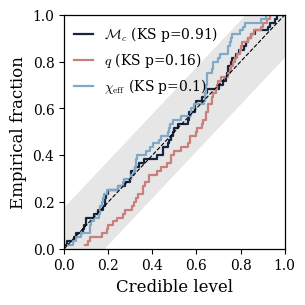

In [3]:
figures.fig_pp_3p({'cred_Mc': levels[:, 0], 'cred_q': levels[:, 1], 'cred_chi': levels[:, 2]})

## Fig. 19 of the paper

Left: the three intrinsic parameters for 300 injections over the full prior of the paper
($M^{\rm det}$ from 20 to $200\,M_\odot$, $q$ from 0.3 to 1, $\chi_{\rm eff}$ from $-0.6$ to $0.6$).
Right: the source-frame primary mass and the redshift for 592 injections, with the distance kept as a parameter.

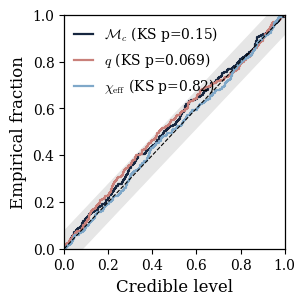

In [4]:
figures.fig_pp_3p(np.load('../data/results/pp_3p.npz'))

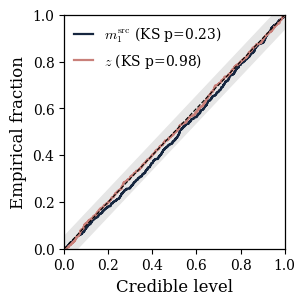

In [5]:
figures.fig_pp_2p(np.load('../data/results/pp_2p.npz'))